In [2]:
import pandas as pd
import os

file_path = os.path.expanduser(
    '~/Documents/clinic/data/processed/clinical_trial_cleaned.csv'
)

df = pd.read_csv(file_path)

print(df.shape)

(60336, 16)


In [2]:
df.head()

,source_condition_query,nct_id,title,official_title,brief_summary,conditions,interventions,overall_status,study_type,phase,sex,minimum_age,maximum_age,healthy_volunteers,eligibility_criteria,clinicaltrials_url
0,breast cancer,NCT03676114,Effect of Perioperative Low Dose Ketamine on P...,Effect of Perioperative Low Dose Ketamine on P...,Breast cancer patients often have perioperativ...,Breast Cancer,ketamine | Normal saline,UNKNOWN,INTERVENTIONAL,PHASE4,FEMALE,20 Years,65 Years,False,Inclusion Criteria:\n\n1. American Society of ...,https://clinicaltrials.gov/study/NCT03676114
1,breast cancer,NCT02941614,Implementing Systematic Distress Screening in ...,Implementing Systematic Distress Screening in ...,Many breast cancer patients experience psychol...,Breast Cancer,Distress screening,COMPLETED,OBSERVATIONAL,Not Specified,ALL,18 Years,NaN,False,Inclusion Criteria:\n\n* Newly diagnosed with ...,https://clinicaltrials.gov/study/NCT02941614
2,breast cancer,NCT04509063,Investigating Public Enthusiasm for Mammograph...,Investigating Public Enthusiasm for Mammograph...,"Based on an American study by Scherer et al., ...",Breast Neoplasm Female | Mammography Screening...,Information about hypothetical mammography scr...,COMPLETED,INTERVENTIONAL,Not Specified,FEMALE,44 Years,49 Years,True,Inclusion Criteria:\n\n* Residence: Central De...,https://clinicaltrials.gov/study/NCT04509063
3,breast cancer,NCT04327063,MIRs 04 : Interpectoral Nerve Block With Ropiv...,A Double-blind Randomized Trial of Interpector...,Compare the effect of ropivacaine versus place...,Malignant Neoplasm of Breast,Saline | Ropivacaine,COMPLETED,INTERVENTIONAL,PHASE3,FEMALE,18 Years,85 Years,False,Inclusion Criteria:\n\n1. Women with non-metas...,https://clinicaltrials.gov/study/NCT04327063
4,breast cancer,NCT06778863,A Study of CLSP-1025 in Adult Patients With So...,GUARDIAN-101: A Phase 1 Dose Escalation and Ex...,Phase 1 dose escalation and expansion study of...,Advanced Solid Tumor | Unresectable Solid Tumo...,CLSP-1025,RECRUITING,INTERVENTIONAL,PHASE1,ALL,18 Years,NaN,False,Key Inclusion Criteria:\n\n* Patients must be ...,https://clinicaltrials.gov/study/NCT06778863


In [4]:
df_model = df[['brief_summary', 'source_condition_query']].copy()

df_model.head()

,brief_summary,source_condition_query
0,Breast cancer patients often have perioperativ...,breast cancer
1,Many breast cancer patients experience psychol...,breast cancer
2,"Based on an American study by Scherer et al., ...",breast cancer
3,Compare the effect of ropivacaine versus place...,breast cancer
4,Phase 1 dose escalation and expansion study of...,breast cancer


In [4]:
df_model.shape

(60336, 2)

Inspect the text before preprocessing

In [5]:
print(df_model['brief_summary'].iloc[0])

Breast cancer patients often have perioperative emotional disorders such as anxiety and depression, which can lead to poor quality of recovery.This study aims to determine whether ketamine could improve the quality of recovery in breast cancer patients. Meanwhile, it will show if ketamine could improve anxiety, depression, postoperative pain and fatigue.This trial also will bring great concerns on patients' mental health perioperatively and explore the measures to improve their quality of life.


For our clinical trial NLP project, we'll:
1. Convert text to lowercase.
2. Remove HTML tags.
3. Remove URLs.
4. Remove unnecessary punctuation and special characters.
5. Remove extra spaces.
6. Preserve medical words and stopwords to avoid losing important clinical meaning.

In [6]:
# Text preprocessing


import re

def preprocess_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r'<[^>]+>', ' ', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+', ' ', text)

    # Remove punctuation and special characters
    text = re.sub(r'[^a-z0-9\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text


# Apply preprocessing
df_model['brief_summary'] = df_model['brief_summary'].apply(preprocess_text)

# Display the result
print(df_model['brief_summary'].iloc[0])



breast cancer patients often have perioperative emotional disorders such as anxiety and depression which can lead to poor quality of recovery this study aims to determine whether ketamine could improve the quality of recovery in breast cancer patients meanwhile it will show if ketamine could improve anxiety depression postoperative pain and fatigue this trial also will bring great concerns on patients mental health perioperatively and explore the measures to improve their quality of life


In [7]:
print("Missing summaries:", df_model['brief_summary'].isnull().sum())
print("Empty summaries:", (df_model['brief_summary'].str.strip() == '').sum())

Missing summaries: 0
Empty summaries: 0


In [8]:
X = df_model['brief_summary']
y = df_model['source_condition_query']

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (60336,)
Output shape: (60336,)


In [9]:
%pip install scikit-learn


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [10]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (48268,)
X_test: (12068,)
y_train: (48268,)
y_test: (12068,)


TF-IDF converts these words into numerical features based on their importance across the training documents.

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=10000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (48268, 10000)
Testing TF-IDF shape: (12068, 10000)


In [12]:
## Train Logistic Regression

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [13]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [14]:
# Model Prediction

# Predict disease categories
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")
print(y_pred[:10])

Predictions completed!
['sickle cell anemia' 'breast cancer'
 'chronic obstructive pulmonary disease' 'breast cancer' 'anxiety'
 'breast cancer' 'breast cancer' 'anxiety' 'rheumatoid arthritis'
 'breast cancer']


In [21]:
from sklearn.metrics import accuracy_score, classification_report

# Training prediction
y_train_pred = model.predict(X_train_tfidf)

# Testing prediction
y_test_pred = model.predict(X_test_tfidf)

# Accuracy
print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))

# Training Classification Report
print("\nTraining Classification Report:")
print(classification_report(y_train, y_train_pred))

# Testing Classification Report
print("\nTesting Classification Report:")
print(classification_report(y_test, y_test_pred))

Training Accuracy: 0.96797049805254
Testing Accuracy: 0.94804441498177

Training Classification Report:
                                       precision    recall  f1-score   support

                              anxiety       0.93      0.97      0.95      7429
                        breast cancer       0.97      0.98      0.98     13040
chronic obstructive pulmonary disease       0.97      0.94      0.95      4945
                             covid-19       0.99      0.96      0.97      8122
                             glaucoma       0.99      0.96      0.97      1738
                 rheumatoid arthritis       0.98      0.93      0.96      2910
                   sickle cell anemia       0.99      0.90      0.94       911
                      type 2 diabetes       0.96      0.99      0.97      9173

                             accuracy                           0.97     48268
                            macro avg       0.97      0.95      0.96     48268
                         

In [15]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)

Model Accuracy: 0.94804441498177
Model Accuracy (%): 94.804441498177


In [17]:
%pip install seaborn


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


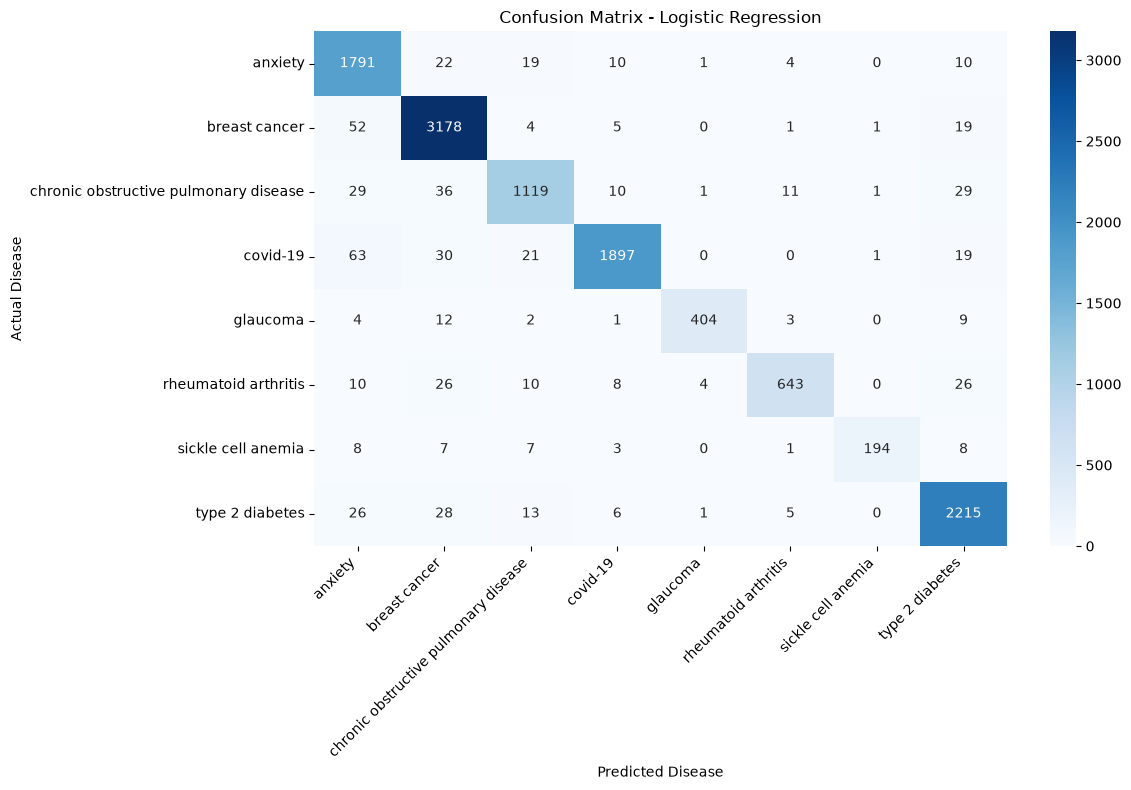

In [18]:

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(12, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel('Predicted Disease')
plt.ylabel('Actual Disease')
plt.title('Confusion Matrix - Logistic Regression')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [19]:
import joblib
import os

model_path = os.path.expanduser('~/Documents/clinic/models')

os.makedirs(model_path, exist_ok=True)

joblib.dump(model, os.path.join(model_path, 'disease_classifier.pkl'))

joblib.dump(tfidf, os.path.join(model_path, 'tfidf_vectorizer.pkl'))

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!


In [20]:
# Test the saved model with new text
import os
import joblib

# Load saved files
loaded_model = joblib.load(
    os.path.join(model_path, 'disease_classifier.pkl')
)

loaded_tfidf = joblib.load(
    os.path.join(model_path, 'tfidf_vectorizer.pkl')
)


def predict_disease(text):

    # Text preprocessing
    cleaned_text = [preprocess_text(text)]

    # Convert text into numerical features
    text_tfidf = loaded_tfidf.transform(cleaned_text)

    # Predict disease category
    prediction = loaded_model.predict(text_tfidf)

    return prediction[0]


# Give a new clinical trial summary
new_text = "This study evaluates a new treatment for breast cancer patients."

# Call the function
result = predict_disease(new_text)

print("Predicted Disease:", result)

Predicted Disease: breast cancer
